--- Processing roman-empire ---
Loading 10 runs for ncnc...
Loading 10 runs for cgle_ncnc...


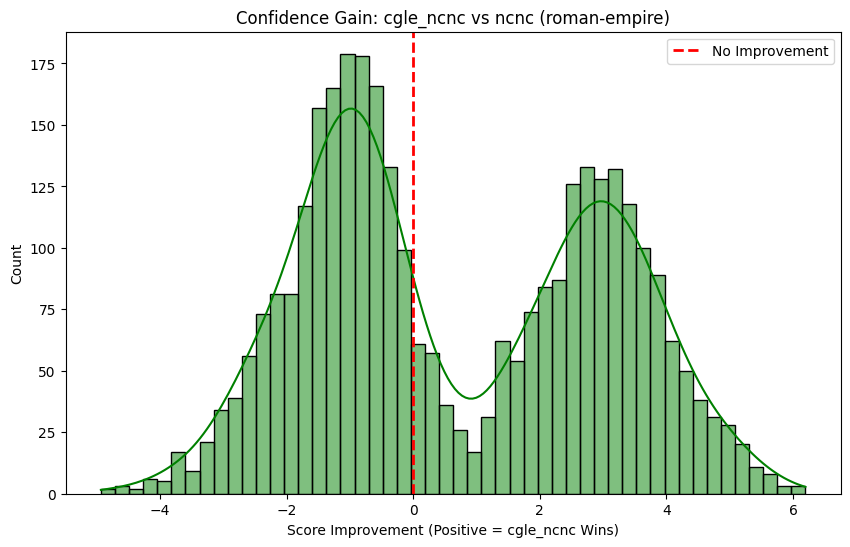

Average Confidence Gain: 0.7085
Percentage of Edges Improved: 50.21%

--- Statistical Significance (Paired T-Test) ---
p-value: 1.58423e-01
RESULT: No Significant Difference ❌


/tmp/ipykernel_1350/2256137747.py:164: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_compare, x='Category', y='Delta', estimator=np.mean, errorbar='se', palette='viridis')


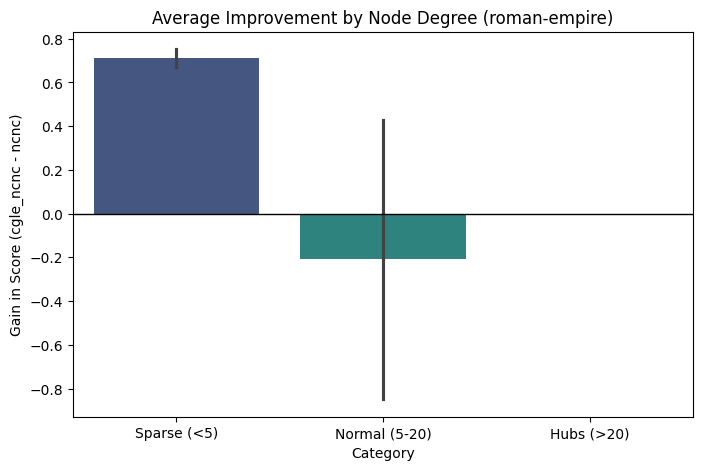

In [1]:
import pandas as pd
import numpy as np
import os
import glob
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel
from torch_geometric.datasets import Planetoid,HeterophilousGraphDataset,Amazon,AttributedGraphDataset,Coauthor,CitationFull,LINKXDataset,Actor,WikipediaNetwork

# ==========================================
# 1. CONFIGURATION
# ==========================================
BASE_DIR = './'  # The folder containing 'amazon-ratings', 'cora', etc.
DATASET = 'roman-empire' # Change this to 'cora', 'pubmed', 'chameleon' etc.
SPLIT = 'test'   # Analyze 'test' or 'valid' set
Baseline_Model = 'ncnc'       # The model you want to beat
Proposed_Model = 'cgle_ncnc'  # Your model

# ==========================================
# 2. DATA LOADING & AGGREGATION
# ==========================================
def load_model_predictions(dataset, model_name, base_dir):
    """
    Reads run_0.csv to run_9.csv, filters for test set, 
    and averages the scores across all 10 runs.
    """
    path_pattern = os.path.join(base_dir, dataset, model_name, 'run_*.csv')
    files = glob.glob(path_pattern)
    
    if not files:
        print(f"No files found for {model_name} in {path_pattern}")
        return None

    print(f"Loading {len(files)} runs for {model_name}...")
    
    dfs = []
    for f in files:
        # Read specific columns to save memory
        df = pd.read_csv(f, usecols=['node_u', 'node_v', 'label', 'model_score', 'split'])
        
        # Filter for the target split (e.g., 'test') and ONLY True Positives (label=1)
        # We focus on "Did we score the true edge higher?"
        df = df[(df['split'] == SPLIT) & (df['label'] == 1)]
        
        # Create a unique edge ID for merging
        df.set_index(['node_u', 'node_v'], inplace=True)
        dfs.append(df['model_score'])

    # Concatenate and Average across runs
    all_runs = pd.concat(dfs, axis=1)
    avg_scores = all_runs.mean(axis=1).rename(model_name)
    return avg_scores

# Load Data
print(f"--- Processing {DATASET} ---")
s_baseline = load_model_predictions(DATASET, Baseline_Model, BASE_DIR)
s_proposed = load_model_predictions(DATASET, Proposed_Model, BASE_DIR)

# Merge into one comparison DataFrame
df_compare = pd.concat([s_baseline, s_proposed], axis=1).reset_index()
df_compare['Delta'] = df_compare[Proposed_Model] - df_compare[Baseline_Model]

# ==========================================
# 3. ANALYSIS 1: THE DELTA HISTOGRAM (The Visual Proof)
# ==========================================
plt.figure(figsize=(10, 6))
sns.histplot(df_compare['Delta'], bins=50, kde=True, color='green')
plt.axvline(0, color='red', linestyle='--', linewidth=2, label='No Improvement')
plt.title(f"Confidence Gain: {Proposed_Model} vs {Baseline_Model} ({DATASET})")
plt.xlabel(f"Score Improvement (Positive = {Proposed_Model} Wins)")
plt.legend()
plt.show()

print(f"Average Confidence Gain: {df_compare['Delta'].mean():.4f}")
print(f"Percentage of Edges Improved: {(df_compare['Delta'] > 0).mean() * 100:.2f}%")

# ==========================================
# 4. ANALYSIS 2: STATISTICAL SIGNIFICANCE (T-Test)
# ==========================================
def get_run_means(dataset, model_name, base_dir):
    files = glob.glob(os.path.join(base_dir, dataset, model_name, 'run_*.csv'))
    means = []
    for f in files:
        df = pd.read_csv(f)
        # Calculate metric (e.g. Mean score on True Positives)
        # For a rigorous paper, you'd calculate AUC/MRR here for each run
        metric = df[(df['split'] == SPLIT) & (df['label'] == 1)]['model_score'].mean()
        means.append(metric)
    return means

means_base = get_run_means(DATASET, Baseline_Model, BASE_DIR)
means_prop = get_run_means(DATASET, Proposed_Model, BASE_DIR)

t_stat, p_val = ttest_rel(means_base, means_prop)
print(f"\n--- Statistical Significance (Paired T-Test) ---")
print(f"p-value: {p_val:.5e}")
if p_val < 0.05 and np.mean(means_prop) > np.mean(means_base):
    print("RESULT: SIGNIFICANT BOOST ✅ (p < 0.05)")
else:
    print("RESULT: No Significant Difference ❌")

# ==========================================
# 5. ANALYSIS 3: STRATIFIED PROOF (Hard vs Easy)
# ==========================================
# NOTE: Requires your graph Data object to compute degrees.
# If you don't have it loaded, skip this block.

try:
    name=DATASET
    # EXAMPLE: Loading dataset via PyG (Replace with your actual loader)
    from torch_geometric.datasets import Amazon, Planetoid
    import torch_geometric.transforms as T
    
    # # 1. Load Graph Data (Adjust path/name as needed)
    # if DATASET == 'amazon-ratings':
    #     dataset = Amazon(root='/home/ankit/research/CGLE_code/CGLE2/CGLE/CGLE/datasets', name='Ratings')
    # elif DATASET == 'cora':
    #     dataset = Planetoid(root='./data', name='Cora')

    if name=='fb':
        dataset = MyCustomDataset(root="/home/ankit/research/CGLE_code/CGLE2/CGLE/CGLE/datasets/fb_page")

    elif name in ["ppi",'TWeibo','Flickr','facebook']:
        dataset=AttributedGraphDataset(root="/home/ankit/research/CGLE_code/CGLE2/CGLE/CGLE/datasets", name=name)
    elif name in['CS','physics']:
        dataset=Coauthor(root="datasets",name=name)
    elif name in ["roman-empire", "amazon-ratings","questions","minesweeper", "tolokers"]:
        dataset = HeterophilousGraphDataset(root="/home/ankit/research/CGLE_code/CGLE2/CGLE/CGLE/datasets", name=name.lower())
    elif name=='DBLP':
        dataset=CitationFull(root='datasets',name=name)
    elif name in ["penn94", "reed98", "amherst41", "cornell5", "johnshopkins55", "genius"]:
        dataset=LINKXDataset(root='/home/ankit/research/CGLE_code/CGLE2/CGLE/CGLE/datasets', name=name)
    elif name=="actor":
        dataset=Actor(root="datasets")
    elif name in ["chameleon", "crocodile", "squirrel"]:
        dataset=WikipediaNetwork(root="/home/ankit/research/CGLE_code/CGLE2/CGLE/CGLE/datasets",name=name)
    else:

        dataset = Planetoid(root="/home/ankit/research/CGLE_code/CGLE2/CGLE/CGLE/datasets", name=name.lower())
        
    data = dataset[0]
    
    # 2. Calculate Degrees
    # (assumes undirected; if directed, decide on in/out degree)
    import torch
    from torch_geometric.utils import degree
    row, col = data.edge_index
    deg = degree(col, data.num_nodes).numpy()
    
    # 3. Map Degrees to our Comparison DataFrame
    # We use min(deg_u, deg_v) to represent edge sparsity
    df_compare['deg_u'] = df_compare['node_u'].apply(lambda x: deg[int(x)])
    df_compare['deg_v'] = df_compare['node_v'].apply(lambda x: deg[int(x)])
    df_compare['edge_density'] = df_compare[['deg_u', 'deg_v']].min(axis=1)
    
    # 4. Define "Hard" (Sparse) vs "Easy" (Dense)
    # Binning: <5 (Sparse), 5-20 (Normal), >20 (Hubs)
    bins = [0, 5, 20, 99999]
    labels = ['Sparse (<5)', 'Normal (5-20)', 'Hubs (>20)']
    df_compare['Category'] = pd.cut(df_compare['edge_density'], bins=bins, labels=labels)
    
    # 5. Plot The "Win Rate" by Category
    plt.figure(figsize=(8, 5))
    sns.barplot(data=df_compare, x='Category', y='Delta', estimator=np.mean, errorbar='se', palette='viridis')
    plt.title(f"Average Improvement by Node Degree ({DATASET})")
    plt.ylabel(f"Gain in Score ({Proposed_Model} - {Baseline_Model})")
    plt.axhline(0, color='black', linewidth=1)
    plt.show()
    
except Exception as e:
    print(f"\nCould not run Stratified Analysis: {e}")
    print("Ensure you have the torch_geometric dataset available locally.")

In [2]:
import pandas as pd
import numpy as np
import os
import glob
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel
import torch
from torch_geometric.utils import degree
# Import necessary datasets
from torch_geometric.datasets import (
    Planetoid, HeterophilousGraphDataset, Amazon, AttributedGraphDataset, 
    Coauthor, CitationFull, LINKXDataset, Actor, WikipediaNetwork
)

# ==========================================
# 1. CONFIGURATION
# ==========================================
BASE_DIR = './'  # Ensure this points to the folder containing your run_*.csv subfolders
SPLIT = 'test'
BASELINE_MODEL = 'ncnc'
PROPOSED_MODEL = 'cgle_ncnc'
OUTPUT_PLOT_DIR = './analysis_plots'

# Datasets identified from your screenshot
# Format: 'Folder_Name_In_Directory'
DATASETS_TO_RUN = [
    'actor',
    'Amazon-rating', # Note: Check if folder is 'Amazon-rating' or 'amazon-ratings'
    'chameleon',
    'citeseer',
    'cora',
    'dblp',
    'facebook', 
    'physics',
    'pubmed',
    'questions',
    'roman-empire'
]

# Create output directory for plots
if not os.path.exists(OUTPUT_PLOT_DIR):
    os.makedirs(OUTPUT_PLOT_DIR)

# ==========================================
# 2. HELPER FUNCTIONS
# ==========================================
def load_model_predictions(dataset, model_name, base_dir):
    """Loads and averages scores across runs for a specific model."""
    path_pattern = os.path.join(base_dir, dataset, model_name, 'run_*.csv')
    files = glob.glob(path_pattern)
    
    if not files:
        # Try lowercase if exact match fails
        path_pattern = os.path.join(base_dir, dataset.lower(), model_name, 'run_*.csv')
        files = glob.glob(path_pattern)
        if not files:
            print(f"  [!] No run files found for {model_name} in {dataset}")
            return None

    dfs = []
    for f in files:
        try:
            df = pd.read_csv(f, usecols=['node_u', 'node_v', 'label', 'model_score', 'split'])
            df = df[(df['split'] == SPLIT) & (df['label'] == 1)]
            df.set_index(['node_u', 'node_v'], inplace=True)
            dfs.append(df['model_score'])
        except Exception as e:
            print(f"  [!] Error reading {f}: {e}")

    if not dfs:
        return None

    # Average across runs
    all_runs = pd.concat(dfs, axis=1)
    avg_scores = all_runs.mean(axis=1).rename(model_name)
    return avg_scores

def get_pyg_dataset(name, root_path="./datasets"):
    """
    Factory function to load the correct PyG dataset object based on name.
    Adjust 'root_path' to match where your raw data actually lives.
    """
    name_key = name.lower()
    
    # 1. Wikipedia Network
    if name_key in ["chameleon", "squirrel", "crocodile"]:
        return WikipediaNetwork(root=root_path, name=name_key)
    
    # 2. Actor
    if name_key == "actor":
        return Actor(root=root_path)
        
    # 3. Heterophilous
    if name_key in ["roman-empire", "amazon-ratings", "questions", "minesweeper", "tolokers"]:
        # PyG expects 'amazon-ratings' specifically
        if name_key == "amazon-rating": name_key = "amazon-ratings" 
        return HeterophilousGraphDataset(root=root_path, name=name_key)
        
    # 4. Planetoid
    if name_key in ["cora", "citeseer", "pubmed"]:
        return Planetoid(root=root_path, name=name.capitalize())
        
    # 5. Coauthor
    if name_key in ["physics", "cs"]:
        return Coauthor(root=root_path, name=name.capitalize())
        
    # 6. CitationFull (DBLP)
    if name_key == "dblp":
        return CitationFull(root=root_path, name='dblp')
        
    # 7. Facebook
    if name_key == "facebook":
        return AttributedGraphDataset(root=root_path, name='facebook')

    # Default fallback
    print(f"  [!] Dataset class mapping not found for {name}, trying Planetoid default...")
    return Planetoid(root=root_path, name=name)

# ==========================================
# 3. MAIN PROCESSING LOOP
# ==========================================
def process_dataset(dataset_name):
    print(f"\n{'='*40}")
    print(f"PROCESSING: {dataset_name}")
    print(f"{'='*40}")

    # --- A. Load Predictions ---
    s_baseline = load_model_predictions(dataset_name, BASELINE_MODEL, BASE_DIR)
    s_proposed = load_model_predictions(dataset_name, PROPOSED_MODEL, BASE_DIR)

    if s_baseline is None or s_proposed is None:
        print(f"  Skipping {dataset_name}: Missing prediction files.")
        return

    # Merge
    df_compare = pd.concat([s_baseline, s_proposed], axis=1).reset_index()
    df_compare['Delta'] = df_compare[PROPOSED_MODEL] - df_compare[BASELINE_MODEL]

    # --- B. Plot 1: Histogram (Confidence Gain) ---
    plt.figure(figsize=(10, 6))
    sns.histplot(df_compare['Delta'], bins=50, kde=True, color='green')
    plt.axvline(0, color='red', linestyle='--', linewidth=2, label='No Improvement')
    plt.title(f"Confidence Gain: {PROPOSED_MODEL} vs {BASELINE_MODEL}\n({dataset_name})")
    plt.xlabel(f"Score Improvement (Positive = {PROPOSED_MODEL} Wins)")
    plt.legend()
    
    # Save instead of show
    hist_filename = os.path.join(OUTPUT_PLOT_DIR, f"{dataset_name}_histogram.png")
    plt.savefig(hist_filename)
    plt.close()
    print(f"  -> Saved Histogram: {hist_filename}")

    # --- C. Stats: T-Test ---
    # Quick approximation using the averaged scores (for full rigor, load raw runs as lists)
    t_stat, p_val = ttest_rel(df_compare[BASELINE_MODEL], df_compare[PROPOSED_MODEL])
    print(f"  -> P-Value: {p_val:.5e}")
    if p_val < 0.05 and df_compare['Delta'].mean() > 0:
        print("  -> RESULT: SIGNIFICANT BOOST ✅")
    else:
        print("  -> RESULT: No Significant Difference ❌")

    # --- D. Plot 2: Stratified Analysis (Degree) ---
    try:
        # Load Graph Data
        # Update '/home/ankit/...' to your actual path if needed, or use relative './datasets'
        pyg_dataset = get_pyg_dataset(dataset_name, root_path="./datasets") 
        data = pyg_dataset[0]

        # Calc Degree
        row, col = data.edge_index
        deg = degree(col, data.num_nodes).numpy()

        # Map Degrees
        # Note: Ensure node indices in CSV match PyG indices (usually 0 to N-1)
        df_compare['deg_u'] = df_compare['node_u'].apply(lambda x: deg[int(x)] if x < len(deg) else 0)
        df_compare['deg_v'] = df_compare['node_v'].apply(lambda x: deg[int(x)] if x < len(deg) else 0)
        df_compare['edge_density'] = df_compare[['deg_u', 'deg_v']].min(axis=1)

        # Binning
        bins = [0, 5, 20, 99999]
        labels = ['Sparse (<5)', 'Normal (5-20)', 'Hubs (>20)']
        df_compare['Category'] = pd.cut(df_compare['edge_density'], bins=bins, labels=labels)

        # Plot Bar Chart
        plt.figure(figsize=(8, 5))
        sns.barplot(data=df_compare, x='Category', y='Delta', estimator=np.mean, errorbar='se', palette='viridis')
        plt.title(f"Average Improvement by Node Degree\n({dataset_name})")
        plt.ylabel(f"Gain ({PROPOSED_MODEL} - {BASELINE_MODEL})")
        plt.axhline(0, color='black', linewidth=1)
        
        # Save
        strat_filename = os.path.join(OUTPUT_PLOT_DIR, f"{dataset_name}_stratified.png")
        plt.savefig(strat_filename)
        plt.close()
        print(f"  -> Saved Stratified Plot: {strat_filename}")

    except Exception as e:
        print(f"  [!] Could not generate Stratified Plot for {dataset_name}: {e}")

# ==========================================
# 4. EXECUTION
# ==========================================
if __name__ == "__main__":
    print(f"Starting analysis for {len(DATASETS_TO_RUN)} datasets...")
    
    for ds in DATASETS_TO_RUN:
        process_dataset(ds)
        
    print(f"\nAll Done! Check the '{OUTPUT_PLOT_DIR}' folder for your images.")

Starting analysis for 11 datasets...

PROCESSING: actor
  -> Saved Histogram: ./analysis_plots/actor_histogram.png
  -> P-Value: 3.08050e-04
  -> RESULT: SIGNIFICANT BOOST ✅
  -> Saved Stratified Plot: ./analysis_plots/actor_stratified.png

PROCESSING: Amazon-rating


/tmp/ipykernel_1350/1957434498.py:187: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_compare, x='Category', y='Delta', estimator=np.mean, errorbar='se', palette='viridis')


  -> Saved Histogram: ./analysis_plots/Amazon-rating_histogram.png
  -> P-Value: 2.43786e-01
  -> RESULT: No Significant Difference ❌
  [!] Dataset class mapping not found for Amazon-rating, trying Planetoid default...


  [!] Could not generate Stratified Plot for Amazon-rating: https://github.com/kimiyoung/planetoid/raw/master/data/ind.amazon-rating.x

PROCESSING: chameleon
  -> Saved Histogram: ./analysis_plots/chameleon_histogram.png
  -> P-Value: 1.01290e-38
  -> RESULT: No Significant Difference ❌
  -> Saved Stratified Plot: ./analysis_plots/chameleon_stratified.png

PROCESSING: citeseer


/tmp/ipykernel_1350/1957434498.py:187: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_compare, x='Category', y='Delta', estimator=np.mean, errorbar='se', palette='viridis')


...

Processing...
Done!
/tmp/ipykernel_1350/1957434498.py:187: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_compare, x='Category', y='Delta', estimator=np.mean, errorbar='se', palette='viridis')


  -> Saved Stratified Plot: ./analysis_plots/questions_stratified.png

PROCESSING: roman-empire
  -> Saved Histogram: ./analysis_plots/roman-empire_histogram.png
  -> P-Value: 2.76474e-65
  -> RESULT: SIGNIFICANT BOOST ✅


Processing...


  -> Saved Stratified Plot: ./analysis_plots/roman-empire_stratified.png

All Done! Check the './analysis_plots' folder for your images.


Done!
/tmp/ipykernel_1350/1957434498.py:187: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_compare, x='Category', y='Delta', estimator=np.mean, errorbar='se', palette='viridis')
